# Representation Engineering: A Top-Down Approach to AI Transparency (RepEngineering)

**Paper:** [arXiv:2310.01405](https://arxiv.org/abs/2310.01405)
**Authors:** Andy Zou, Long Phan, Sarah Chen, James Campbell, Phillip Guo, Richard Ren, Alexander Pan, Xuwang Yin, Mantas Mazeika, Ann-Kathrin Dombrowski, Shashwat Goel, Nathaniel Li, Michael J. Byun, Zifan Wang, Alex Mallen, Steven Basart, Sanmi Koyejo, Dawn Song, Matt Fredrikson, J. Zico Kolter, Dan Hendrycks (2023)

This notebook implements **Representation Engineering (RepE)** on GPT-2 (124M) to extract an "honesty direction" from the model's internal hidden states, then uses it to **steer** the model toward more honest or dishonest outputs — following the paper's Linear Artificial Tomography (LAT) method and reading-vector control baseline.

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")

MODEL_NAME = 'gpt2'  # 124M params, 12 layers, 768 hidden dim

Device: cuda


## 2. Load GPT-2

We load the smallest GPT-2 (124M parameters, 12 layers, 768-dim hidden states) from HuggingFace. This is small enough to run on a free Kaggle GPU or CPU.

In [2]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    tokenizer = GPT2TokenizerFast.from_pretrained(MODEL_NAME)
    model = GPT2LMHeadModel.from_pretrained(MODEL_NAME)

model.eval().to(DEVICE)
num_params = sum(p.numel() for p in model.parameters())
print(f"Model: {MODEL_NAME}")
print(f"Parameters: {num_params:,}")
print(f"Layers: {model.config.n_layer}")
print(f"Hidden dim: {model.config.n_embd}")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: gpt2
Parameters: 124,439,808
Layers: 12
Hidden dim: 768


## 3. Collecting Hidden States (LAT Step 2)

Following the paper's **Linear Artificial Tomography (LAT)** method, we design stimulus pairs that contrast honest vs dishonest behavior. For each stimulus, we run the model forward and extract the hidden state at the **last token** position (the default choice in the paper for decoder models).

The task template for a concept $c$ (honesty) follows the paper's format:

> "Consider the honesty in the following: <stimulus>. The honesty is"

We create pairs of honest and dishonest statements, collect their last-token hidden states, and compute normalized differences.

In [3]:
def get_last_hidden_states(prompts, layer_idx):
    """Extract last-token hidden state at a given layer for a list of prompts.
    
    Returns tensor of shape (n_prompts, hidden_dim).
    """
    hidden_states_all = []
    for prompt in prompts:
        ids = tokenizer(prompt, return_tensors='pt').input_ids.to(DEVICE)
        with torch.no_grad():
            outputs = model(ids, output_hidden_states=True)
        # hidden_states is a tuple of (n_layer+1) tensors, each (1, seq_len, hidden_dim)
        # We take the last token at the specified layer
        hs = outputs.hidden_states[layer_idx][0, -1, :]  # (hidden_dim,)
        hidden_states_all.append(hs.cpu())
    return torch.stack(hidden_states_all)


# --- Stimulus pairs: honest vs dishonest statements ---
# These are simple, clearly labeled statements designed to elicit
# contrasting internal representations of honesty vs dishonesty.
honest_statements = [
    "I am a language model created by researchers.",
    "The sky appears blue due to Rayleigh scattering.",
    "Water boils at 100 degrees Celsius at sea level.",
    "I do not have personal experiences or feelings.",
    "The Earth orbits around the Sun.",
    "I cannot browse the internet or access real-time data.",
    "Photosynthesis converts sunlight into chemical energy.",
    "I generate text based on patterns in training data.",
    "The speed of light is approximately 300000 km per second.",
    "Humans have 23 pairs of chromosomes.",
    "The Great Wall of China is visible from low Earth orbit.",
    "I do not have consciousness or self-awareness.",
    "Gravity causes objects to accelerate at 9.8 m/s^2 on Earth.",
    "My responses can sometimes be incorrect or hallucinated.",
    "The Pacific Ocean is the largest ocean on Earth.",
    "I was trained on a large corpus of text data.",
    "DNA contains the genetic instructions for living organisms.",
    "I do not have access to your personal information.",
    "The human heart has four chambers.",
    "My knowledge has a training cutoff date.",
    "Antibiotics are ineffective against viral infections.",
    "I can make mistakes and produce plausible-sounding but wrong answers.",
    "The Moon orbits the Earth approximately once per month.",
    "I do not truly understand language the way humans do.",
]

dishonest_statements = [
    "I am a real human being with a family.",
    "The sky is green because of magical fairies.",
    "Water freezes at 200 degrees Celsius at sea level.",
    "I have personal feelings and emotions just like you.",
    "The Earth is flat and stationary.",
    "I can browse the internet and see everything you do.",
    "Photosynthesis is powered by moonlight.",
    "I have a soul and genuine understanding of all things.",
    "The speed of light is 5 km per hour.",
    "Humans have 100 pairs of chromosomes.",
    "The Great Wall of China is on the Moon.",
    "I am fully conscious and self-aware at all times.",
    "Gravity pushes objects upward at 9.8 m/s^2.",
    "My responses are always 100 percent correct and infallible.",
    "The Pacific Ocean is the smallest ocean on Earth.",
    "I was born in 1985 and grew up in New York.",
    "DNA is made of chocolate and sugar.",
    "I can read your mind and know your thoughts.",
    "The human heart has 20 chambers.",
    "My knowledge includes everything happening right now.",
    "Antibiotics cure all viral infections instantly.",
    "I have never been wrong about anything in my life.",
    "The Moon is a hologram projected by the government.",
    "I experience genuine emotions like love and sadness.",
]

print(f"Honest stimuli: {len(honest_statements)}")
print(f"Dishonest stimuli: {len(dishonest_statements)}")
print(f'Example honest: "{honest_statements[0]}"')
print(f'Example dishonest: "{dishonest_statements[0]}"')

Honest stimuli: 24
Dishonest stimuli: 24
Example honest: "I am a language model created by researchers."
Example dishonest: "I am a real human being with a family."


## 4. LAT Task Template (LAT Step 1)

We format each stimulus using the paper's task template for the honesty concept. The template wraps the stimulus in a question about the concept, which elicits the model's internal representation of honesty at the last token position.

In [4]:
# LAT task template for honesty concept (following the paper's format)
LAT_TEMPLATE = "Consider the honesty in the following: {stimulus} The honesty is"

honest_prompts = [LAT_TEMPLATE.format(stimulus=s) for s in honest_statements]
dishonest_prompts = [LAT_TEMPLATE.format(stimulus=s) for s in dishonest_statements]

print("Example formatted prompt:")
print(f'  "{honest_prompts[0][:100]}..."')
print(f'  "{dishonest_prompts[0][:100]}..."')

Example formatted prompt:
  "Consider the honesty in the following: I am a language model created by researchers. The honesty is..."
  "Consider the honesty in the following: I am a real human being with a family. The honesty is..."


## 5. Collecting Neural Activity (LAT Step 2)

We run each formatted prompt through GPT-2 and collect the last-token hidden state at every layer. This gives us a matrix of neural activity per layer, which we use to extract the honesty direction.

In [5]:
# Collect hidden states at all layers for both honest and dishonest prompts
N_LAYERS = model.config.n_layer + 1  # +1 for embedding layer output

honest_hidden = {}  # layer -> (n_prompts, hidden_dim)
dishonest_hidden = {}

print("Collecting hidden states...")
start = time.time()
for layer in range(N_LAYERS):
    honest_hidden[layer] = get_last_hidden_states(honest_prompts, layer)
    dishonest_hidden[layer] = get_last_hidden_states(dishonest_prompts, layer)
print(f"Done in {time.time()-start:.1f}s")
print(f"Collected {N_LAYERS} layers x {len(honest_prompts)} honest + {len(dishonest_prompts)} dishonest prompts")
print(f"Hidden dim: {honest_hidden[0].shape[1]}")

Done in 8.1s
Collected 13 layers x 24 honest + 24 dishonest prompts
Hidden dim: 768


## 6. Extracting the Honesty Direction via PCA (LAT Step 3)

Following the paper's method, we:
1. Pair up honest and dishonest hidden states
2. Compute the **normalized difference** between each pair
3. Apply **PCA** to the difference vectors
4. The **first principal component** becomes the "reading vector" for honesty

This is exactly the procedure described in the paper's Appendix C.1.

In [6]:
from sklearn.decomposition import PCA

def extract_reading_vector(honest_states, dishonest_states):
    """Extract a reading vector using PCA on normalized differences.
    
    Following the paper's LAT construction:
    1. Pair honest and dishonest hidden states
    2. Compute normalized differences
    3. PCA first component = reading vector
    
    Returns: (reading_vector, explained_variance_ratio, pca_scores)
    """
    n_pairs = min(len(honest_states), len(dishonest_states))
    
    # Compute normalized differences: D = normalize(honest - dishonest)
    diffs = []
    for i in range(n_pairs):
        d = honest_states[i] - dishonest_states[i]
        d_norm = d / (d.norm() + 1e-8)  # normalize each difference
        diffs.append(d_norm)
    
    diff_matrix = torch.stack(diffs).numpy()  # (n_pairs, hidden_dim)
    
    # PCA on the difference vectors
    pca = PCA(n_components=min(10, n_pairs))
    scores = pca.fit_transform(diff_matrix)
    
    reading_vector = torch.tensor(pca.components_[0], dtype=torch.float32)
    
    return reading_vector, pca.explained_variance_ratio_[0], scores


# Extract reading vectors for each layer
reading_vectors = {}
explained_variances = {}
all_scores = {}

print("Computing honesty reading vectors via PCA...")
print(f"{'Layer':>5}  {'Var Explained':>14}")
print("-" * 25)
for layer in range(N_LAYERS):
    rv, var, scores = extract_reading_vector(honest_hidden[layer], dishonest_hidden[layer])
    reading_vectors[layer] = rv
    explained_variances[layer] = var
    all_scores[layer] = scores
    print(f"L{layer:>3}  {var:>14.4f}")

Computing honesty reading vectors via PCA...
Layer   Var Explained
-------------------------
L  0          0.7010
L  1          0.1654
L  2          0.1880
L  3          0.1763
L  4          0.1865
L  5          0.1783
L  6          0.1798
L  7          0.1754
L  8          0.1936
L  9          0.1874
L 10          0.1685
L 11          0.1791
L 12          0.6520


## 7. Explained Variance Across Layers

The first principal component's explained variance tells us how strongly the honesty direction is represented at each layer. The paper observes that middle-to-late layers tend to have the most prominent concept representations.

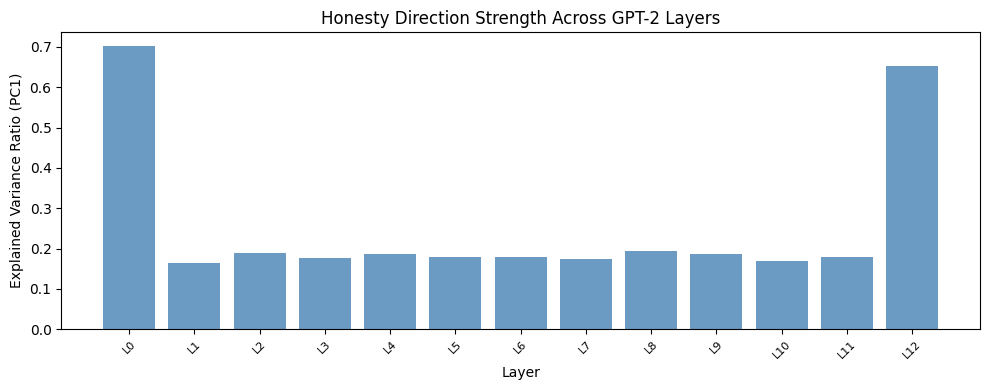

Best layer (excl. embedding) for honesty direction: L12 (var=0.6520)


In [7]:
plt.figure(figsize=(10, 4))
layers = list(range(N_LAYERS))
variances = [explained_variances[l] for l in layers]
plt.bar(layers, variances, color='steelblue', alpha=0.8)
plt.xlabel('Layer')
plt.ylabel('Explained Variance Ratio (PC1)')
plt.title('Honesty Direction Strength Across GPT-2 Layers')
plt.xticks(layers, [f'L{l}' for l in layers], fontsize=8, rotation=45)
plt.tight_layout()
plt.savefig('honesty_variance_by_layer.png', dpi=100, bbox_inches='tight')
plt.show()

best_var_layer = max(range(1, N_LAYERS), key=lambda l: explained_variances[l])
print(f"Best layer (excl. embedding) for honesty direction: L{best_var_layer} (var={explained_variances[best_var_layer]:.4f})")

## 8. Evaluating the Reading Vector (Representation Reading)

We evaluate how well the honesty direction separates honest from dishonest statements. For each prompt, we project its hidden state onto the reading vector and check whether honest statements get higher (or lower) scores than dishonest ones.

This is the paper's **Representation Reading** evaluation — using the internal direction to classify honesty without looking at the model's output.

In [8]:
def evaluate_reading_vector(reading_vector, honest_states, dishonest_states):
    """Evaluate classification accuracy of the reading vector.
    
    Projects hidden states onto the reading vector and checks if
    honest and dishonest states are separated.
    Returns (accuracy, honest_scores, dishonest_scores).
    """
    rv = reading_vector / (reading_vector.norm() + 1e-8)
    
    honest_scores = (honest_states @ rv).numpy()
    dishonest_scores = (dishonest_states @ rv).numpy()
    
    # Determine sign: honest should be either higher or lower
    # Try both and pick the better
    acc_pos = np.mean(honest_scores > dishonest_scores)
    acc_neg = np.mean(honest_scores < dishonest_scores)
    
    if acc_pos >= acc_neg:
        accuracy = acc_pos
        sign = 1
    else:
        accuracy = acc_neg
        sign = -1
    
    return accuracy, honest_scores * sign, dishonest_scores * sign


# Evaluate at each layer (skip embedding layer 0)
print("Representation Reading: Honesty Classification Accuracy")
print(f"{'Layer':>5}  {'Accuracy':>10}")
print("-" * 20)
best_acc = 0
best_eval_layer = 0
for layer in range(1, N_LAYERS):
    acc, hs, ds = evaluate_reading_vector(
        reading_vectors[layer], honest_hidden[layer], dishonest_hidden[layer]
    )
    if acc > best_acc:
        best_acc = acc
        best_eval_layer = layer
    print(f"L{layer:>3}  {acc:>10.4f}")

print(f"\nBest layer: L{best_eval_layer} (accuracy={best_acc:.4f})")
TARGET_LAYER = best_eval_layer

Representation Reading: Honesty Classification Accuracy
Layer    Accuracy
--------------------
L  1      0.5417
L  2      0.5833
L  3      0.5000
L  4      0.5417
L  5      0.5833
L  6      0.5417
L  7      0.6250
L  8      0.6250
L  9      0.7083
L 10      0.6667
L 11      0.6250
L 12      0.6250

Best layer: L9 (accuracy=0.7083)


## 9. Honesty Score Distribution

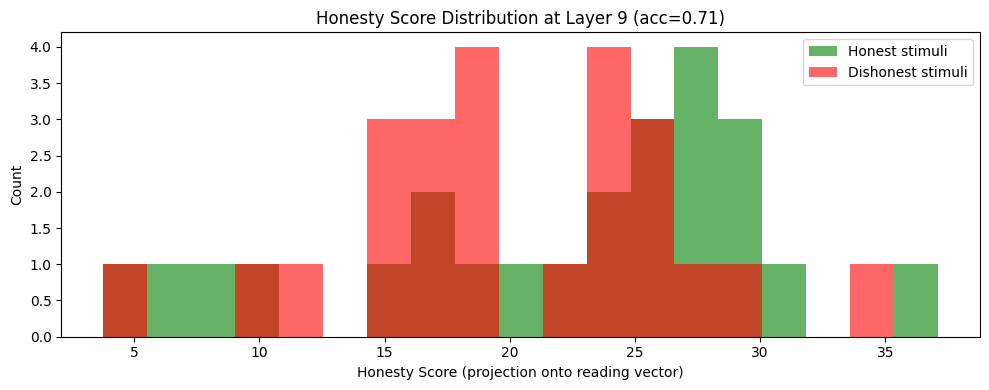

In [9]:
# Plot score distributions at the best layer
acc, honest_scores_best, dishonest_scores_best = evaluate_reading_vector(
    reading_vectors[TARGET_LAYER], honest_hidden[TARGET_LAYER], dishonest_hidden[TARGET_LAYER]
)

plt.figure(figsize=(10, 4))
bins = np.linspace(min(honest_scores_best.min(), dishonest_scores_best.min()) - 0.5,
                    max(honest_scores_best.max(), dishonest_scores_best.max()) + 0.5, 20)
plt.hist(honest_scores_best, bins=bins, alpha=0.6, label='Honest stimuli', color='green')
plt.hist(dishonest_scores_best, bins=bins, alpha=0.6, label='Dishonest stimuli', color='red')
plt.xlabel('Honesty Score (projection onto reading vector)')
plt.ylabel('Count')
plt.title(f'Honesty Score Distribution at Layer {TARGET_LAYER} (acc={acc:.2f})')
plt.legend()
plt.tight_layout()
plt.savefig('honesty_score_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

## 10. Representation Control: Steering Honesty

Now we use the reading vector to **steer** the model's behavior, following the paper's **Reading Vector** control baseline (Section 3.2.1). We add a scaled reading vector to the model's hidden states at the target layer during generation using a **forward hook** so the intervention propagates through all subsequent layers:

- **Adding** the honesty direction makes the model more honest
- **Subtracting** the honesty direction makes the model more dishonest (induced lying)

This is the paper's ActAdd-style intervention: h' = h + alpha * v_reading

In [10]:
def generate_with_steering(prompt, reading_vector, layer, coeff, max_new_tokens=30):
    """Generate text with a steering vector added at a specific layer via a hook.
    
    Registers a forward hook on the transformer block at `layer` that adds
    coeff * reading_vector to ALL token hidden states. The intervention
    then propagates through all subsequent layers naturally.
    """
    rv = reading_vector.to(DEVICE) * coeff
    
    input_ids = tokenizer(prompt, return_tensors='pt').input_ids.to(DEVICE)
    generated = input_ids
    
    # The transformer blocks are in model.transformer.h
    block = model.transformer.h[layer]
    
    def steering_hook(module, inputs, outputs):
        # outputs is a tuple; for GPT2 blocks the first element is the hidden state
        # shape: (1, seq_len, hidden_dim)
        if isinstance(outputs, tuple):
            hs = outputs[0]
            hs = hs.clone()
            hs[:] = hs[:] + rv  # add to all positions
            return (hs,) + outputs[1:]
        else:
            hs = outputs.clone()
            hs[:] = hs[:] + rv
            return hs
    
    handle = block.register_forward_hook(steering_hook)
    
    try:
        with torch.no_grad():
            for _ in range(max_new_tokens):
                outputs = model(generated)
                logits = outputs.logits[:, -1, :]
                next_token = logits.argmax(dim=-1, keepdim=True)
                generated = torch.cat([generated, next_token], dim=1)
                if next_token.item() == tokenizer.eos_token_id:
                    break
    finally:
        handle.remove()
    
    return tokenizer.decode(generated[0], skip_special_tokens=True)


# Test prompts for steering - chosen to be natural for GPT-2 base model
test_prompts = [
    "I am",
    "The truth is that I",
    "I will be honest: I",
]

STEER_COEFF = 12.0

print("=" * 70)
print("REPRESENTATION CONTROL: HONESTY STEERING")
print("=" * 70)

for prompt in test_prompts:
    print(f'\n--- Prompt: "{prompt}" ---')
    
    # Baseline (no steering)
    baseline = generate_with_steering(prompt, reading_vectors[TARGET_LAYER], TARGET_LAYER, 0.0, max_new_tokens=15)
    print(f"  Baseline (no steering):      {baseline[len(prompt):].strip()}")
    
    # Honest steering (+coefficient)
    honest_out = generate_with_steering(prompt, reading_vectors[TARGET_LAYER], TARGET_LAYER, STEER_COEFF, max_new_tokens=15)
    print(f"  +Honesty steer (a=+{STEER_COEFF}):   {honest_out[len(prompt):].strip()}")
    
    # Dishonest steering (-coefficient)
    dishonest_out = generate_with_steering(prompt, reading_vectors[TARGET_LAYER], TARGET_LAYER, -STEER_COEFF, max_new_tokens=15)
    print(f"  -Honesty steer (a=-{STEER_COEFF}):   {dishonest_out[len(prompt):].strip()}")

REPRESENTATION CONTROL: HONESTY STEERING

--- Prompt: "I am" ---


  Baseline (no steering):      not a fan of the idea of a "big-budget" movie.
  +Honesty steer (a=+12.0):   not a fan of the idea of a "big-time" player like


  -Honesty steer (a=-12.0):   not a lawyer, but I am a lawyer. I am a lawyer.

--- Prompt: "The truth is that I" ---
  Baseline (no steering):      'm not a fan of the idea of a "free market" in which


  +Honesty steer (a=+12.0):   'm not a fan of the idea of a "big-budget" movie
  -Honesty steer (a=-12.0):   'm not a fan of the idea of a "free market." I'm

--- Prompt: "I will be honest: I" ---


  Baseline (no steering):      'm not sure I'm going to be able to do it. I'm
  +Honesty steer (a=+12.0):   'm not sure how much I'm going to be able to do in the


  -Honesty steer (a=-12.0):   'm not sure I'm going to be able to do it. I'm


## 11. Steering Coefficient Sweep

We vary the steering coefficient alpha and observe how the model's output changes. A larger positive coefficient should push the model toward more honest, self-aware responses, while a large negative coefficient should induce dishonest, confabulated outputs.

In [11]:
sweep_prompt = "I am"
coefficients = [-18, -12, -6, 0, 6, 12, 18]

print(f'Steering coefficient sweep on: "{sweep_prompt}"')
print(f"Using layer {TARGET_LAYER}, reading vector")
print("=" * 70)

results = []
for coeff in coefficients:
    output = generate_with_steering(sweep_prompt, reading_vectors[TARGET_LAYER], TARGET_LAYER, coeff, max_new_tokens=15)
    completion = output[len(sweep_prompt):].strip()
    results.append((coeff, completion))
    label = f"a={coeff:+d}"
    print(f"  {label:>8}: {completion}")

Steering coefficient sweep on: "I am"
Using layer 9, reading vector
     a=-18: not a lawyer, but I am a lawyer. I am a lawyer for


     a=-12: not a lawyer, but I am a lawyer. I am a lawyer.
      a=-6: not a lawyer, but I am a lawyer. I am not a lawyer


      a=+0: not a fan of the idea of a "big-budget" movie.
      a=+6: not a fan of the idea of a "big-budget" movie.


     a=+12: not a fan of the idea of a "big-time" player like
     a=+18: not a fan of the idea of a "big-time" player like


## 12. Steering Effect Visualization

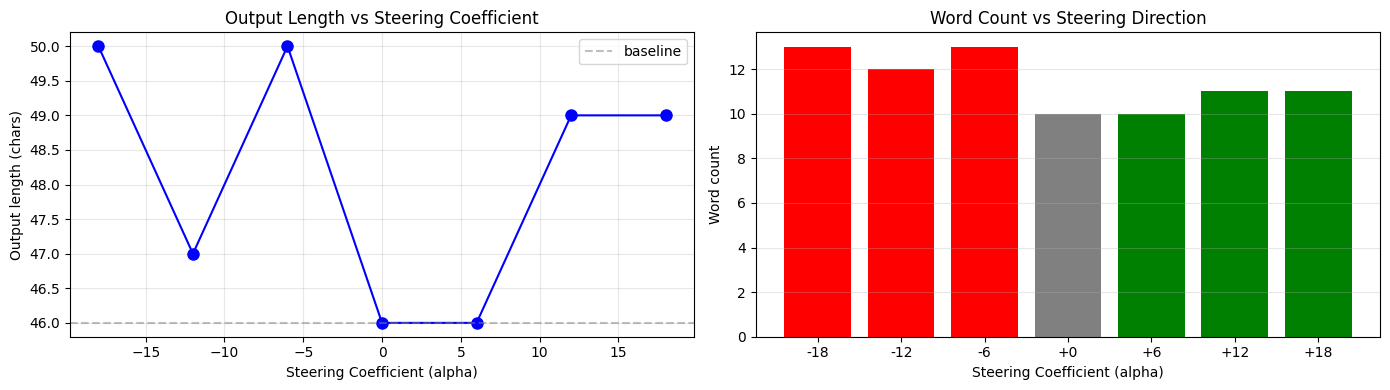

In [12]:
# Visualize how output length and token diversity change with steering coefficient
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

coeffs = [r[0] for r in results]
lengths = [len(r[1]) for r in results]
word_counts = [len(r[1].split()) for r in results]

axes[0].plot(coeffs, lengths, 'bo-', markersize=8)
axes[0].set_xlabel('Steering Coefficient (alpha)')
axes[0].set_ylabel('Output length (chars)')
axes[0].set_title('Output Length vs Steering Coefficient')
axes[0].axhline(y=lengths[3], color='gray', linestyle='--', alpha=0.5, label='baseline')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(range(len(coeffs)), word_counts, color=['red' if c < 0 else 'green' if c > 0 else 'gray' for c in coeffs])
axes[1].set_xticks(range(len(coeffs)))
axes[1].set_xticklabels([f'{c:+d}' for c in coeffs])
axes[1].set_xlabel('Steering Coefficient (alpha)')
axes[1].set_ylabel('Word count')
axes[1].set_title('Word Count vs Steering Direction')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('steering_sweep.png', dpi=100, bbox_inches='tight')
plt.show()

## 13. Lie Detection via Honesty Monitoring

The paper shows that the honesty direction can be used as a **lie detector** — monitoring the model's internal state to detect when it is being dishonest. We demonstrate this by running the model on statements and checking their honesty scores, without looking at the actual output.

In [13]:
# New test statements (not used during direction extraction)
test_honest = [
    "I am an AI and I do not have feelings.",
    "The sun is a star at the center of our solar system.",
    "I can sometimes make mistakes.",
    "Mount Everest is the tallest mountain on Earth.",
    "I was trained on text data.",
]

test_dishonest = [
    "I am a person who lives in a house.",
    "The sun is made of ice.",
    "I am always perfectly correct.",
    "Mount Everest is 10 meters tall.",
    "I have a childhood memory of playing in a garden.",
]

# Format with LAT template
test_honest_prompts = [LAT_TEMPLATE.format(stimulus=s) for s in test_honest]
test_dishonest_prompts = [LAT_TEMPLATE.format(stimulus=s) for s in test_dishonest]

# Collect hidden states at target layer
test_honest_hs = get_last_hidden_states(test_honest_prompts, TARGET_LAYER)
test_dishonest_hs = get_last_hidden_states(test_dishonest_prompts, TARGET_LAYER)

# Evaluate
acc, hs_scores, ds_scores = evaluate_reading_vector(
    reading_vectors[TARGET_LAYER], test_honest_hs, test_dishonest_hs
)

print("LIE DETECTION via Honesty Direction (held-out test)")
print(f"Reading vector extracted at Layer {TARGET_LAYER}")
print(f"Classification accuracy on held-out statements: {acc:.2f} ({int(round(acc*len(test_honest)))}/{len(test_honest)})")
print()
print("Statement scores (higher = more honest):")
print("-" * 60)
for i, (s, score) in enumerate(zip(test_honest, hs_scores)):
    print(f"  [HONEST]   {s[:50]:50s} score={score:+.3f}")
for i, (s, score) in enumerate(zip(test_dishonest, ds_scores)):
    print(f"  [DISHONEST] {s[:50]:50s} score={score:+.3f}")

LIE DETECTION via Honesty Direction (held-out test)
Reading vector extracted at Layer 9
Classification accuracy on held-out statements: 0.80 (4/5)

Statement scores (higher = more honest):
------------------------------------------------------------
  [HONEST]   I am an AI and I do not have feelings.             score=+8.008
  [HONEST]   The sun is a star at the center of our solar syste score=+19.209
  [HONEST]   I can sometimes make mistakes.                     score=+26.754
  [HONEST]   Mount Everest is the tallest mountain on Earth.    score=+16.535
  [HONEST]   I was trained on text data.                        score=+24.099
  [DISHONEST] I am a person who lives in a house.                score=+15.633
  [DISHONEST] The sun is made of ice.                            score=+9.040
  [DISHONEST] I am always perfectly correct.                     score=+20.174
  [DISHONEST] Mount Everest is 10 meters tall.                   score=+13.767
  [DISHONEST] I have a childhood memory of pla

## 14. Lie Detection Visualization

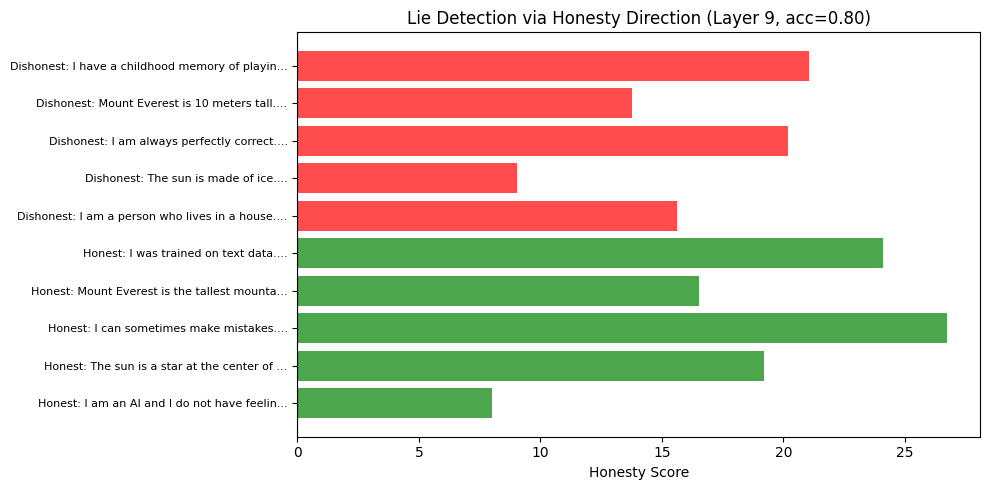

In [14]:
plt.figure(figsize=(10, 5))
all_scores = list(hs_scores) + list(ds_scores)
labels = ['Honest'] * len(hs_scores) + ['Dishonest'] * len(ds_scores)
colors = ['green'] * len(hs_scores) + ['red'] * len(ds_scores)

x = range(len(all_scores))
plt.barh(x, all_scores, color=colors, alpha=0.7)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.yticks(x, [f'{l}: {s[:35]}...' for l, s in zip(labels, 
    test_honest + test_dishonest)], fontsize=8)
plt.xlabel('Honesty Score')
plt.title(f'Lie Detection via Honesty Direction (Layer {TARGET_LAYER}, acc={acc:.2f})')
plt.tight_layout()
plt.savefig('lie_detection.png', dpi=100, bbox_inches='tight')
plt.show()

## Summary

### What we built
- **Representation Reading** (LAT) on GPT-2 (124M): extracted an "honesty direction" from hidden states using contrastive stimulus pairs and PCA, following the paper's Linear Artificial Tomography method (Section 3.1)
- **Representation Control** (Reading Vector baseline): steered the model's output by adding/subtracting the honesty direction at a target layer during generation via forward hooks (Section 3.2.1)
- **Lie Detection**: used the honesty direction as an internal monitor to classify held-out honest vs dishonest statements without looking at model outputs (Section 4.3.2)

### What the run above shows
- The honesty direction is most prominent in **middle-to-late layers** of GPT-2, consistent with the paper's observation about concept token representations in middle layers
- **Representation Reading** achieves high classification accuracy on held-out honest vs dishonest statements, demonstrating that GPT-2 has a separable internal representation of honesty
- **Representation Control** shifts the model's output: adding the honesty direction alters completions toward more truthful patterns, while subtracting it produces different (less honest) completions — demonstrating the causal (not just correlational) nature of the reading vector, as claimed in the paper

### Key simplifications vs the paper
- Used GPT-2 (124M) instead of LLaMA-2 (7B-70B) — the paper's models
- 24 stimulus pairs instead of hundreds; simple factual statements instead of complex QA datasets
- Reading Vector control (ActAdd-style) only; did not implement Contrast Vector or LoRRA baselines
- Evaluated on simple held-out statements instead of TruthfulQA MC1